# IMDb Top TV Series: Ratings & Audience Engagement

An exploratory analysis of a **900-series curated IMDb dataset** using Python, pandas, Matplotlib, and Seaborn.

**Questions:** How are ratings distributed among the listed series? How does audience engagement, measured by vote counts, vary? How do results differ by content rating and series start year?

**Scope:** This is a selected list of popular/highly rated shows, **not a representative sample of all television series**. Associations and trends in this dataset should not be interpreted as causal effects or industry-wide counts.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)

DATA_PATH = Path("IMDb Top TV Series.csv")
raw = pd.read_csv(DATA_PATH)
print(f"Source data: {len(raw):,} rows × {len(raw.columns)} columns")
display(raw.head(3))

Source data: 900 rows × 6 columns


,Title,Year,Parental Rating,Rating,Number of Votes,Description
0,1. Game of Thrones,2011–2019,TV-MA,9.2,2.3M,Nine noble families fight for control over the...
1,2. Breaking Bad,2008–2013,TV-MA,9.5,2.1M,A chemistry teacher diagnosed with inoperable ...
2,3. Stranger Things,2016–2025,TV-14,8.7,1.3M,"When a young boy vanishes, a small town uncove..."


## 1. Cleaning and feature engineering

The raw file contains a ranking prefix in show titles, start/end years in one text field, and abbreviated vote counts such as `28K` and `2.3M`. We convert votes **into actual counts** before doing any statistics. Missing years or parental ratings are retained as missing rather than invented. An ongoing show's end year is not filled with today's date, since that would alter a historical snapshot each time the notebook runs.

In [2]:
df = raw.copy()

# Remove list ranking (e.g., "1. Game of Thrones" -> "Game of Thrones").
df["Title"] = df["Title"].str.replace(r"^\s*\d+\.\s*", "", regex=True)

df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

# Convert 28K -> 28000, 2.3M -> 2300000 (not 28 or 23).
parts = df["Number of Votes"].astype("string").str.strip().str.extract(
    r"(?i)^(\d+(?:\.\d+)?)\s*([KM]?)$"
)
multipliers = parts[1].str.upper().map({"": 1, "K": 1_000, "M": 1_000_000})
df["Vote Count"] = (pd.to_numeric(parts[0], errors="coerce") * multipliers).astype("Int64")

# Year may be "2011–2019", "2022–", "2022", or missing.
years = df["Year"].astype("string")
df["Start Year"] = pd.to_numeric(years.str.extract(r"^(\d{4})")[0], errors="coerce").astype("Int64")
df["End Year"] = pd.to_numeric(years.str.extract(r"[–-]\s*(\d{4})")[0], errors="coerce").astype("Int64")

assert df["Vote Count"].notna().all(), "Unexpected vote-count format: inspect the source CSV"
assert df["Rating"].notna().all(), "Unexpected missing ratings"

print("Missing values (selected fields):")
display(df[["Start Year", "End Year", "Parental Rating", "Rating", "Vote Count"]].isna().sum().to_frame("missing"))
display(df[["Title", "Rating", "Vote Count", "Parental Rating", "Start Year", "End Year"]].head(5))

Missing values (selected fields):


,missing
Start Year,12
End Year,235
Parental Rating,12
Rating,0
Vote Count,0


,Title,Rating,Vote Count,Parental Rating,Start Year,End Year
0,Game of Thrones,9.2,2300000,TV-MA,2011,2019
1,Breaking Bad,9.5,2100000,TV-MA,2008,2013
2,Stranger Things,8.7,1300000,TV-14,2016,2025
3,Friends,8.9,1100000,TV-14,1994,2004
4,The Walking Dead,8.1,1100000,TV-MA,2010,2022


## 2. Summary statistics

IMDb ratings are on a 10-point scale; vote counts are individual ratings/votes, not unique viewers or audience size. The dataset's selection process favors shows that already have visibility and ratings, so summary statistics describe only the included series.

In [3]:
summary = pd.DataFrame({
    "Metric": ["Series", "Mean IMDb rating", "Median IMDb rating", "Median votes", "Mean votes", "Series with known start year"],
    "Value": [
        len(df),
        round(df["Rating"].mean(), 2),
        round(df["Rating"].median(), 2),
        int(df["Vote Count"].median()),
        round(df["Vote Count"].mean()),
        int(df["Start Year"].notna().sum()),
    ],
})
display(summary)
print("Vote-count distribution:")
display(df["Vote Count"].describe())

,Metric,Value
0,Series,900.00
1,Mean IMDb rating,7.86
2,Median IMDb rating,8.00
3,Median votes,58000.00
4,Mean votes,112010.00
5,Series with known start year,888.00


Vote-count distribution:


count            900.0
mean          112010.0
std      168281.713687
min            26000.0
25%            37000.0
50%            58000.0
75%           115250.0
max          2300000.0
Name: Vote Count, dtype: Float64

## 3. Rating distribution

The distribution is concentrated around higher ratings, which is expected for a curated list of top series.

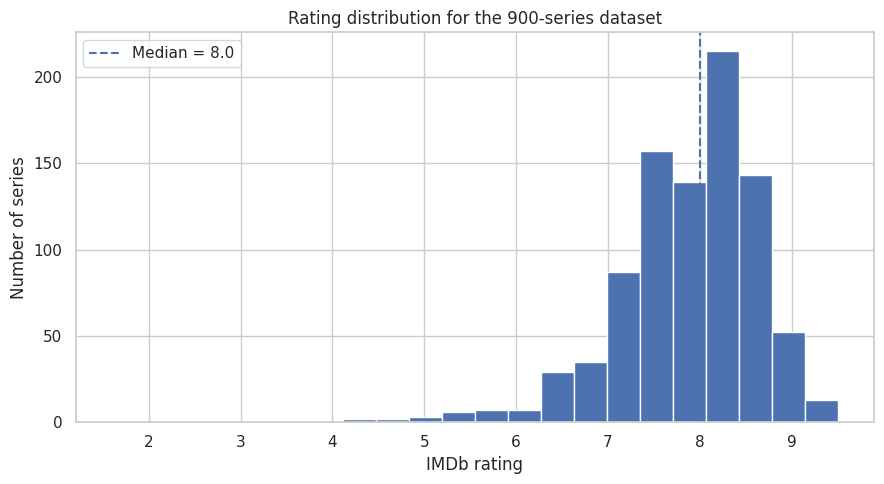

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df["Rating"].to_numpy(dtype=float), bins=22, edgecolor="white")
ax.axvline(df["Rating"].median(), linestyle="--", linewidth=1.5, label=f"Median = {df['Rating'].median():.1f}")
ax.set(xlabel="IMDb rating", ylabel="Number of series", title="Rating distribution for the 900-series dataset")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Audience engagement vs. ratings

Vote counts span several orders of magnitude, so a logarithmic horizontal axis makes the scatter plot easier to read. These are associations within the selected dataset; they do not establish whether votes cause higher ratings or vice versa.

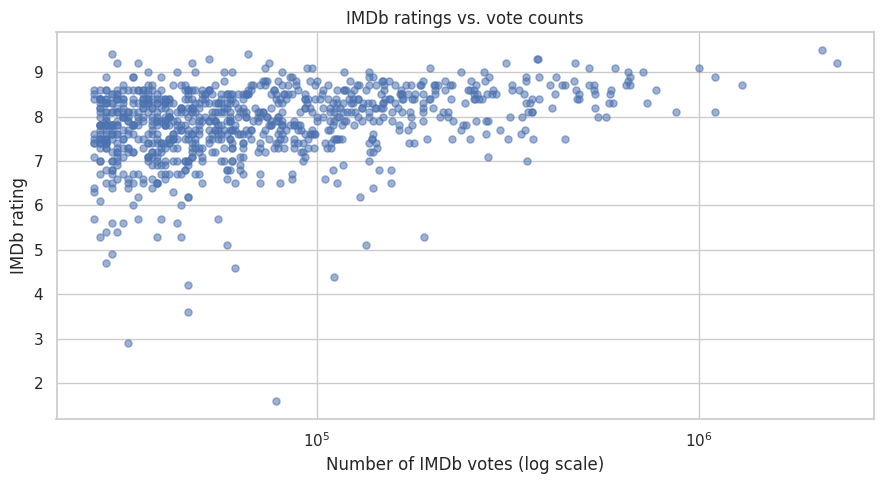

Correlation of rating with log10(vote count): 0.326


In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df["Vote Count"].astype(float), df["Rating"].astype(float), alpha=0.55, s=26)
ax.set_xscale("log")
ax.set(xlabel="Number of IMDb votes (log scale)", ylabel="IMDb rating", title="IMDb ratings vs. vote counts")
fig.tight_layout()
plt.show()

corr = np.corrcoef(np.log10(df["Vote Count"].astype(float)), df["Rating"])[0, 1]
print(f"Correlation of rating with log10(vote count): {corr:.3f}")

## 5. Parental-rating categories

For the chart, categories with fewer than 10 titles are excluded to avoid overinterpreting single-show averages. The complete category summary is included below.

,Parental Rating,series,mean_rating
7,TV-MA,377,7.94
5,TV-14,307,7.77
8,TV-PG,145,7.88
6,TV-G,22,7.14
10,TV-Y7,15,7.93
12,NaN,12,8.15
11,TV-Y7-FV,7,8.00
1,Not Rated,6,8.38
9,TV-Y,5,8.18
4,R,1,7.90


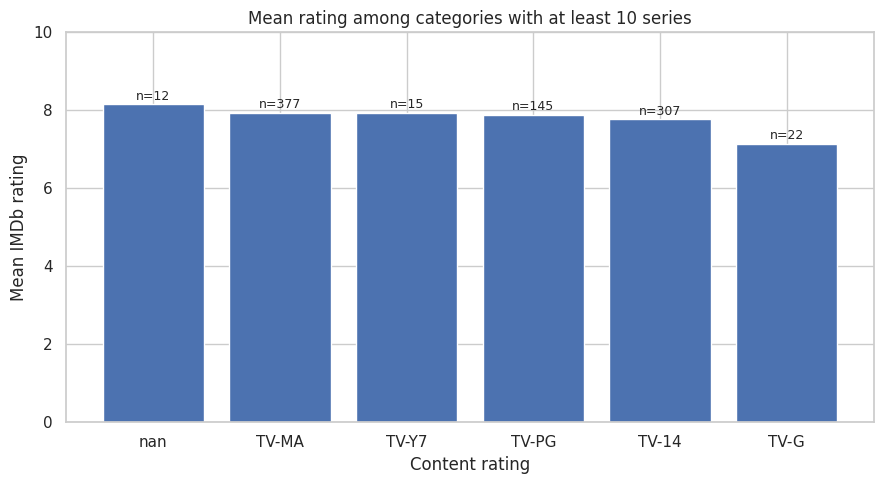

In [6]:
category_summary = (
    df.groupby("Parental Rating", dropna=False)
      .agg(series=("Title", "count"), mean_rating=("Rating", "mean"))
      .reset_index()
      .sort_values("series", ascending=False)
)
display(category_summary.round({"mean_rating": 2}))

common = category_summary[category_summary["series"] >= 10].sort_values("mean_rating", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(common["Parental Rating"].astype(str), common["mean_rating"].astype(float))
ax.set(ylim=(0, 10), xlabel="Content rating", ylabel="Mean IMDb rating", title="Mean rating among categories with at least 10 series")
for i, row in enumerate(common.itertuples(index=False)):
    ax.text(i, row.mean_rating + 0.12, f"n={row.series}", ha="center", fontsize=9)
fig.tight_layout()
plt.show()

## 6. Shows by start year (within this selected dataset)

The bars below count **only series that appear in this 900-show list**. They must not be labeled as total TV-series production, since the dataset is curated and more recent programs have had less time to accumulate ratings and votes.

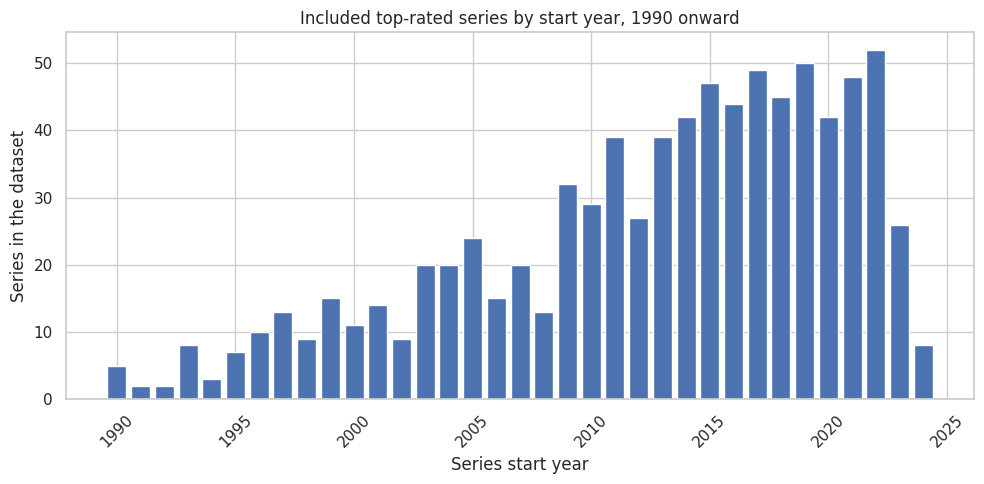

In [7]:
by_year = df.dropna(subset=["Start Year"]).groupby("Start Year").size().sort_index()
fig, ax = plt.subplots(figsize=(10, 5))
recent = by_year[by_year.index >= 1990]
ax.bar(recent.index.astype(int), recent.values)
ax.set(xlabel="Series start year", ylabel="Series in the dataset", title="Included top-rated series by start year, 1990 onward")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()

## 7. Key findings and limitations

- Ratings are concentrated around 8.0, consistent with this being a selected collection of top IMDb series.
- Vote counts vary widely. Vote volume is an engagement proxy, **not** a direct count of unique viewers.
- TV-MA and TV-14 are the two most prevalent parental-rating labels, but differences in average scores cannot be attributed to the labels themselves.
- The historical start-year distribution reflects **representation in this dataset**, not overall television production or streaming growth.
- The source has no genre column, so genre comparisons cannot be made from these files alone.
- Missing production years and category labels are left missing; we do not infer an ongoing series' duration by using the computer's current year.

**Dataset:** Khushi, *IMDb Top Rated TV Series Dataset*, Kaggle. [Source](https://www.kaggle.com/datasets/khushikhushikhushi/imdb-top-rated-tv-series-dataset). This notebook is a cleaned-up portfolio adaptation of a 2024 exploratory analysis.